In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor,
    GradientBoostingRegressor, HistGradientBoostingRegressor
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv(r"D:\Material of Machine Learning Course\my_projects\Project cars data\cars_data.csv")
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,NaN,3000.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            979 non-null    str    
 1   Year             974 non-null    float64
 2   Mileage          979 non-null    float64
 3   Engine_Size      964 non-null    float64
 4   Fuel_Type        982 non-null    str    
 5   Transmission     962 non-null    str    
 6   Previous_Owners  950 non-null    str    
 7   Price            987 non-null    float64
dtypes: float64(4), str(4)
memory usage: 62.6 KB


In [4]:
df.isnull().sum()

Brand              21
Year               26
Mileage            21
Engine_Size        36
Fuel_Type          18
Transmission       38
Previous_Owners    50
Price              13
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

## Data Cleaning

In [6]:
data = df.copy()
data = data.replace(r"^\s*$", np.nan, regex=True)
data = data.drop_duplicates()

data["Previous_Owners"] = pd.to_numeric(data["Previous_Owners"], errors="coerce")
data = data.dropna(subset=["Price"])
data = data[data["Price"] > 0].copy()

X = data.drop(columns=["Price"])
y = data["Price"]

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_medians = X[numeric_cols].median()
categorical_modes = {
    col: X[col].mode(dropna=True).iloc[0]
    for col in categorical_cols
}

X_clean = X.copy()

for col in numeric_cols:
    X_clean[col] = X_clean[col].fillna(numeric_medians[col])

for col in categorical_cols:
    X_clean[col] = X_clean[col].fillna(categorical_modes[col])

print("Cleaned shape:", data.shape)
print("Remaining missing values:", X_clean.isna().sum().sum())
display(X_clean.head())

Cleaned shape: (987, 8)
Remaining missing values: 0


,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,3.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1.0


## EDA

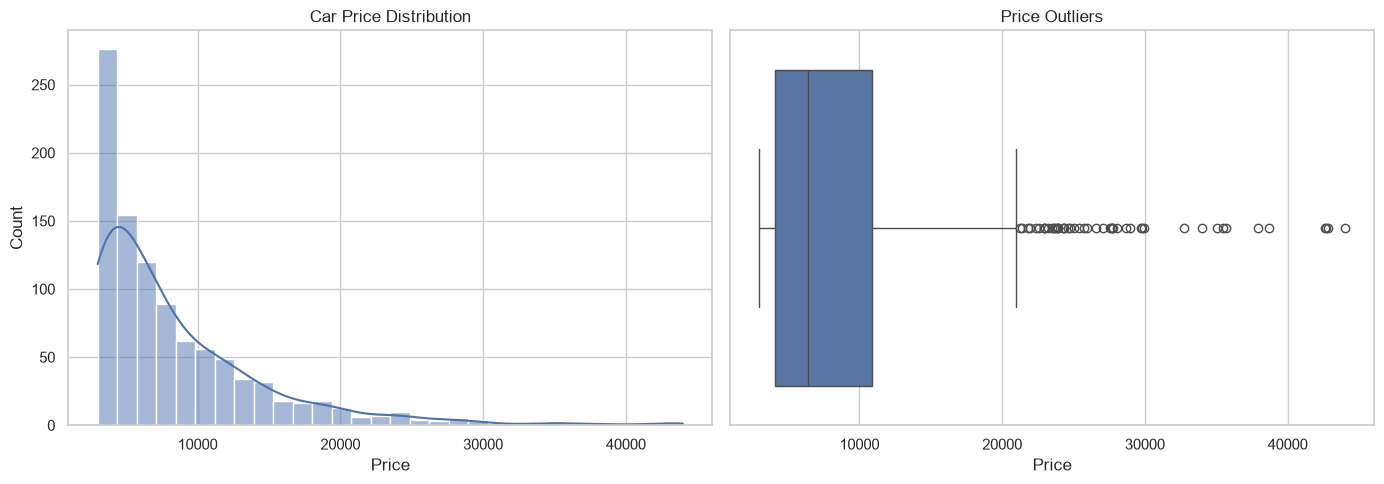

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data["Price"], kde=True, ax=axes[0])
axes[0].set_title("Car Price Distribution")
sns.boxplot(x=data["Price"], ax=axes[1])
axes[1].set_title("Price Outliers")
plt.tight_layout()
plt.show()

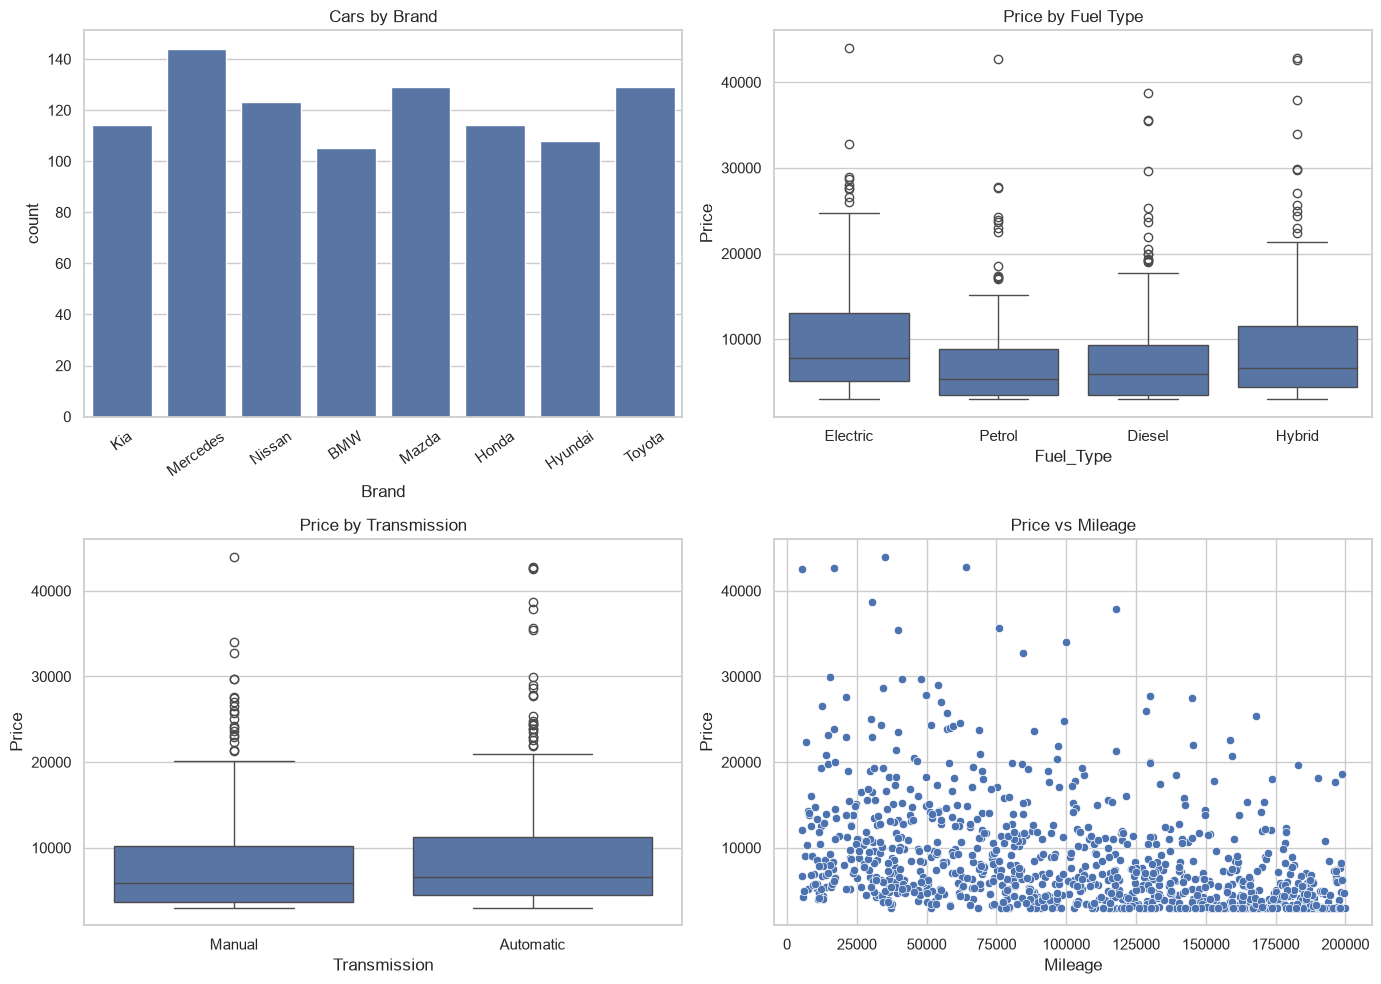

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(data=data, x="Brand", ax=axes[0, 0])
axes[0, 0].set_title("Cars by Brand")
axes[0, 0].tick_params(axis="x", rotation=35)

sns.boxplot(data=data, x="Fuel_Type", y="Price", ax=axes[0, 1])
axes[0, 1].set_title("Price by Fuel Type")

sns.boxplot(data=data, x="Transmission", y="Price", ax=axes[1, 0])
axes[1, 0].set_title("Price by Transmission")

sns.scatterplot(data=data, x="Mileage", y="Price", ax=axes[1, 1])
axes[1, 1].set_title("Price vs Mileage")
plt.tight_layout()
plt.show()

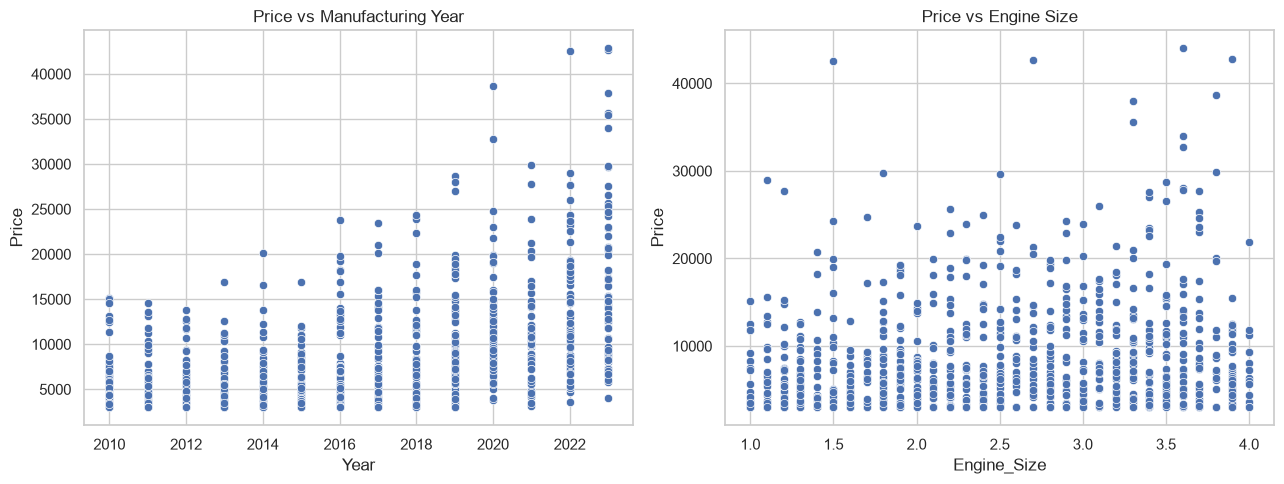

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=data, x="Year", y="Price", ax=axes[0])
axes[0].set_title("Price vs Manufacturing Year")
sns.scatterplot(data=data, x="Engine_Size", y="Price", ax=axes[1])
axes[1].set_title("Price vs Engine Size")
plt.tight_layout()
plt.show()

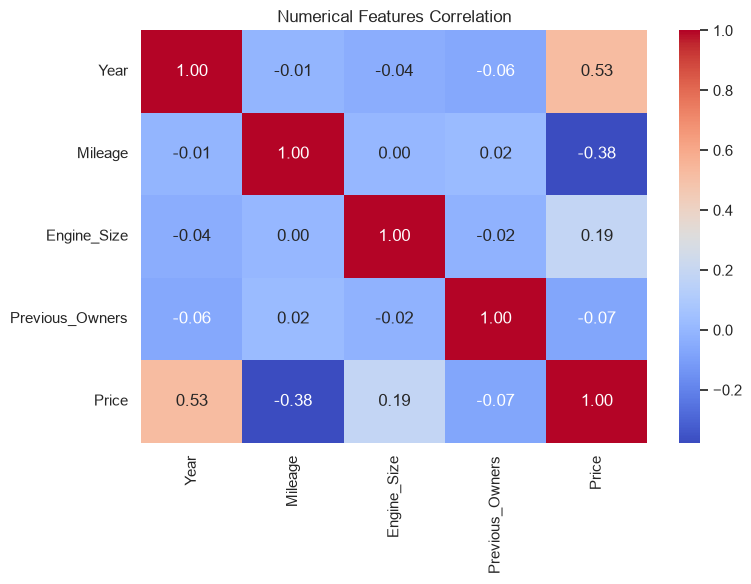

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(data.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Features Correlation")
plt.tight_layout()
plt.show()

## Traditional Preprocessing

In [11]:
X_encoded = pd.get_dummies(
    X_clean,
    columns=categorical_cols,
    drop_first=False
)

feature_columns = X_encoded.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (789, 18)
X_test: (198, 18)


## Regression Models

In [12]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=20000),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(kernel="rbf", C=100),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, random_state=RANDOM_STATE)
}

In [13]:
def regression_metrics(model, X_data, y_actual):
    predictions = model.predict(X_data)
    mae = mean_absolute_error(y_actual, predictions)
    mse = mean_squared_error(y_actual, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, predictions)
    return mae, mse, rmse, r2

errors = {}
trained_models = {}

for model_name, model in models.items():
    print("Training:", model_name)
    model.fit(X_train_scaled, y_train)
    trained_models[model_name] = model

    train_metrics = regression_metrics(model, X_train_scaled, y_train)
    test_metrics = regression_metrics(model, X_test_scaled, y_test)

    errors[model_name] = {
        "MAE Train": train_metrics[0], "MAE Test": test_metrics[0],
        "MSE Train": train_metrics[1], "MSE Test": test_metrics[1],
        "RMSE Train": train_metrics[2], "RMSE Test": test_metrics[2],
        "R2 Train": train_metrics[3], "R2 Test": test_metrics[3]
    }

Training: Linear Regression
Training: Ridge
Training: Lasso
Training: KNN
Training: SVR
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
Training: AdaBoost
Training: Gradient Boosting
Training: Hist Gradient Boosting


## Model Comparison

In [14]:
errors_df = pd.DataFrame(errors).T.sort_values("R2 Test", ascending=False)
display(errors_df)

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Hist Gradient Boosting,638.292234,1457.934298,1.653435e+06,6.578177e+06,1285.859757,2564.795627,0.956697,0.854827
Gradient Boosting,1072.402392,1541.938805,3.201628e+06,7.082807e+06,1789.309370,2661.354304,0.916150,0.843690
Extra Trees,107.538400,1656.540367,3.014411e+04,8.409635e+06,173.620588,2899.937116,0.999211,0.814408
Random Forest,621.430800,1818.495105,1.240460e+06,1.091071e+07,1113.759512,3303.136844,0.967513,0.759212
Linear Regression,2123.137547,2323.221605,1.053806e+07,1.200172e+07,3246.238293,3464.349444,0.724011,0.735135
Lasso,2123.097798,2323.226425,1.053806e+07,1.200198e+07,3246.238317,3464.387947,0.724011,0.735129
Ridge,2122.083299,2323.118656,1.053810e+07,1.200559e+07,3246.244553,3464.908384,0.724010,0.735049
AdaBoost,3156.264873,3215.690413,1.421115e+07,1.864109e+07,3769.768468,4317.532355,0.627814,0.588611
KNN,2101.901394,3171.182828,1.062490e+07,2.503656e+07,3259.586421,5003.654993,0.721737,0.447470
Decision Tree,353.749974,2864.092213,4.533597e+05,3.056602e+07,673.319945,5528.654476,0.988127,0.325440


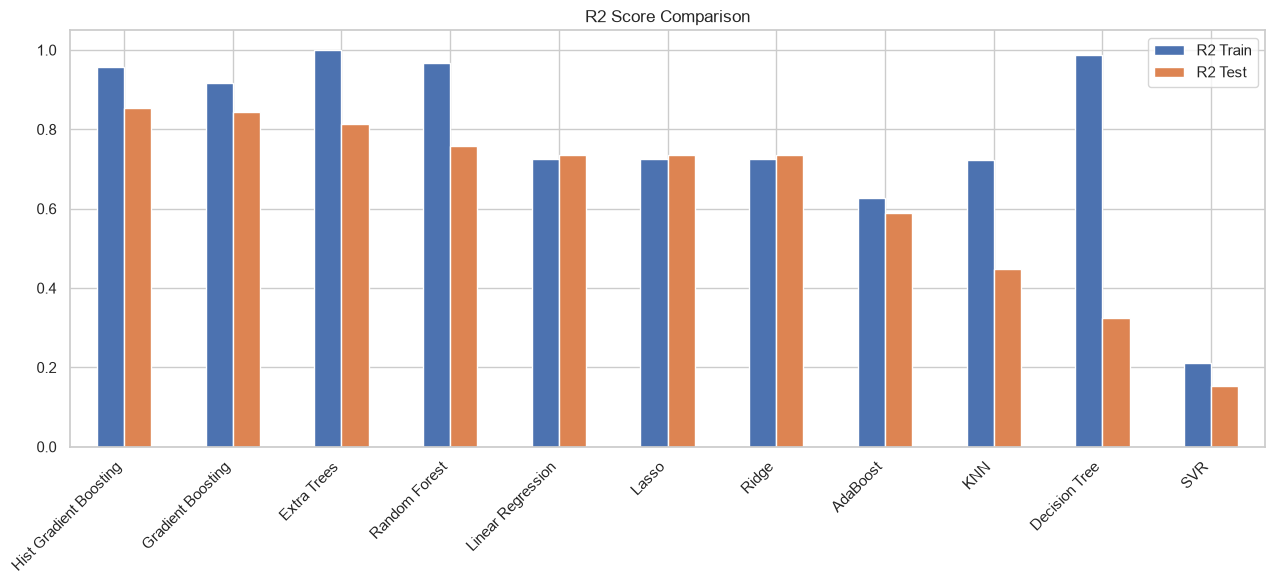

In [15]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(13, 6))
plt.title("R2 Score Comparison")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

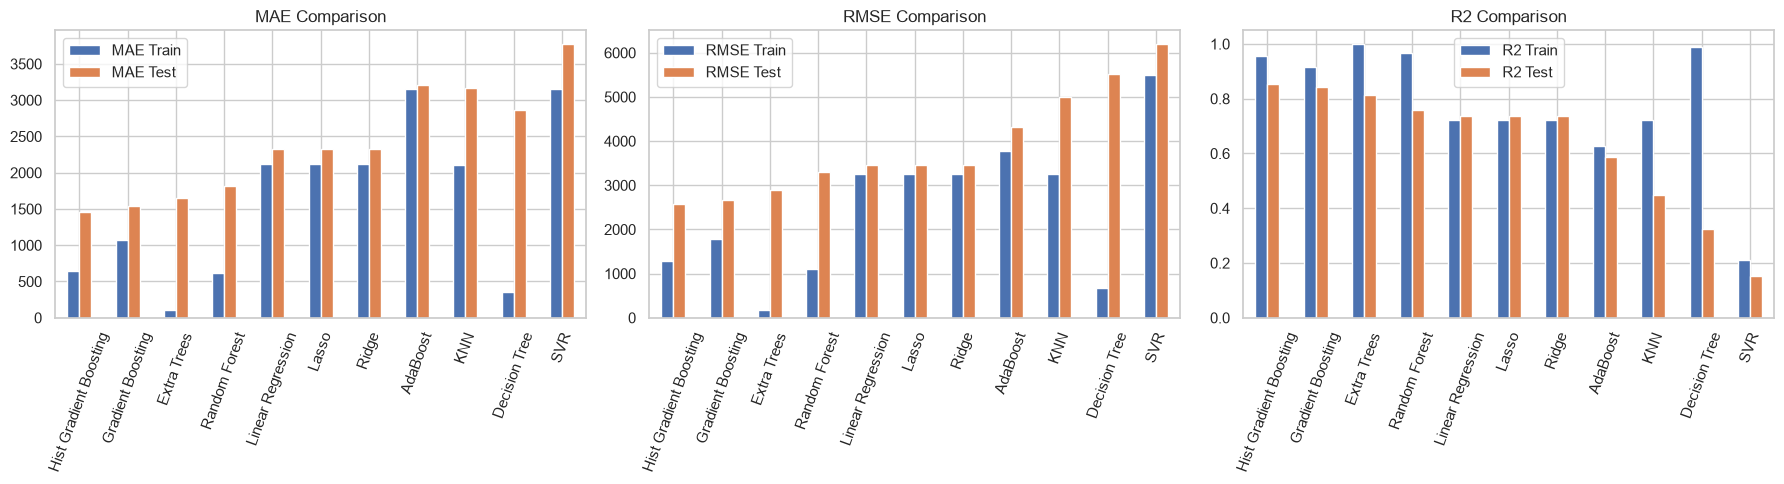

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, cols in zip(
    axes,
    [["MAE Train", "MAE Test"], ["RMSE Train", "RMSE Test"], ["R2 Train", "R2 Test"]]
):
    errors_df[cols].plot.bar(ax=ax)
    ax.set_title(cols[0].split()[0] + " Comparison")
    ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

## Best Model and Saving the Model

In [17]:
best_model_name = errors_df["R2 Test"].idxmax()
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
display(errors_df.loc[[best_model_name]])

predictions = best_model.predict(X_test_scaled)
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predictions
})
comparison["Absolute Error"] = (comparison["Actual Price"] - comparison["Predicted Price"]).abs()
display(comparison.head(10))

Best Model: Hist Gradient Boosting


,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Hist Gradient Boosting,638.292234,1457.934298,1.653435e+06,6.578177e+06,1285.859757,2564.795627,0.956697,0.854827


,Actual Price,Predicted Price,Absolute Error
0,13086.0,15709.911816,2623.911816
1,7063.0,6545.391595,517.608405
2,5570.0,5768.808182,198.808182
3,8001.0,6797.513070,1203.486930
4,24785.0,20609.566204,4175.433796
5,15241.0,14183.859117,1057.140883
6,9103.0,9588.514728,485.514728
7,11221.0,8239.539259,2981.460741
8,3000.0,2792.559390,207.440610
9,20073.0,23559.937665,3486.937665


In [19]:
artifacts = {
    "model": best_model,
    "model_name": best_model_name,
    "scaler": scaler,
    "num_cols": numeric_cols,
    "cat_cols": categorical_cols,
    "num_medians": numeric_medians.to_dict(),
    "cat_modes": categorical_modes,
    "feature_columns": feature_columns
}

joblib.dump(artifacts, "car_price_model.joblib")

['car_price_model.joblib']